# Sales Forecasting using Gradient-Boosted Trees
### Phase 1: Data Understanding, Cleaning & Exploratory Data Analysis (EDA)

**Group Project — B.Tech 2nd Year, Sem 1**

**Objective:** Build a sales forecasting system using Gradient-Boosted Trees (XGBoost / LightGBM),
tuned with Grid-Search Hyperparameter Optimization, and evaluated using MAE, RMSE and R².

This notebook covers the **first half of the ML lifecycle**: understanding the raw data, cleaning it,
and exploring it visually to uncover patterns before any model is built.

| Stage in this notebook | Related Course Outcome (CO) |
|---|---|
| End-to-end lifecycle overview (below) | **CO1** — data → features → training → evaluation → deployment → monitoring |
| Data loading & inspection | CO1 |
| Data cleaning (missing values, duplicates, outliers) | CO1 (feature prep, part of CO5's "data quality" concerns) |
| Exploratory Data Analysis (distributions, trends, correlations) | CO1, groundwork for CO5 (model evaluation needs to know feature-target relationships) |
| *Not yet covered here* — Linear models (CO2), Tree-based models incl. Gradient-Boosted Trees (CO3), Clustering (CO4), CV/hyperparameter tuning/evaluation metrics (CO5), MLOps/deployment (CO6) | To be done in **Phase 2** |

---
### ML System Lifecycle for this project (CO1)
```
Raw Sales Data  →  Cleaning & Feature Engineering  →  Train/Val/Test Split
      →  Model Training (Gradient-Boosted Trees)  →  Grid-Search Hyperparameter Tuning
      →  Evaluation (MAE, RMSE, R²)  →  Deployment (REST API)  →  Monitoring (drift, performance)
```
This notebook implements the first two boxes of that lifecycle.


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Load the Dataset
The dataset `sales_forecasting_dataset_1500.csv` contains **1500 daily sales records** across
10 products, 30 stores, 5 regions and 5 product categories, spanning 2023–2025.

In [2]:
df = pd.read_csv('sales_forecasting_dataset_1500.csv')
print("Shape of dataset:", df.shape)
df.head()


Shape of dataset: (1500, 19)


,Date,Product_ID,Product_Category,Region,Store_ID,Day_of_Week,Month,Quarter,Year,Unit_Price,Discount_Percent,Promotion,Holiday,Marketing_Spend,Competitor_Price,Units_Sold,Inventory_Level,Customer_Count,Sales
0,2023-01-01,P1004,Clothing,Central,S016,Sunday,1,1,2023,37.10,5.0,No,No,1123.63,45.79,62,111.0,161,2056.64
1,2023-01-01,P1006,Clothing,South,S015,Sunday,1,1,2023,44.10,5.0,No,No,441.25,45.58,43,347.0,132,1851.04
2,2023-01-02,P1002,Beauty,East,S007,Monday,1,1,2023,12.16,5.0,Yes,No,1329.83,12.93,82,170.0,264,937.32
3,2023-01-02,P1006,Electronics,Central,S016,Monday,1,1,2023,71.27,5.0,No,No,1306.47,74.39,60,335.0,136,4374.08
4,2023-01-02,P1010,Clothing,South,S013,Monday,1,1,2023,39.08,15.0,No,No,119.19,36.14,64,283.0,151,2228.88


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              1500 non-null   str    
 1   Product_ID        1500 non-null   str    
 2   Product_Category  1500 non-null   str    
 3   Region            1500 non-null   str    
 4   Store_ID          1500 non-null   str    
 5   Day_of_Week       1500 non-null   str    
 6   Month             1500 non-null   int64  
 7   Quarter           1500 non-null   int64  
 8   Year              1500 non-null   int64  
 9   Unit_Price        1500 non-null   float64
 10  Discount_Percent  1488 non-null   float64
 11  Promotion         1500 non-null   str    
 12  Holiday           1500 non-null   str    
 13  Marketing_Spend   1488 non-null   float64
 14  Competitor_Price  1488 non-null   float64
 15  Units_Sold        1500 non-null   int64  
 16  Inventory_Level   1488 non-null   float64
 17  Custom

## 3. Initial Data Understanding

Before cleaning anything, we look at:
- Statistical summary of numeric columns
- Categories present in each categorical column
- How many missing values exist, and where
- Whether duplicate rows exist


In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Month,1500.0,6.417333,3.506665,1.00,3.0000,6.000,9.0000,12.00
Quarter,1500.0,2.478667,1.127117,1.00,1.0000,2.000,3.0000,4.00
Year,1500.0,2024.041333,0.829508,2023.00,2023.0000,2024.000,2025.0000,2025.00
Unit_Price,1500.0,48.304800,20.962717,8.00,33.1675,46.565,63.0050,109.09
Discount_Percent,1488.0,11.700269,8.843644,0.00,5.0000,10.000,20.0000,30.00
Marketing_Spend,1488.0,890.863690,413.640339,111.51,575.2500,826.800,1132.9475,2742.55
Competitor_Price,1488.0,49.288784,22.081192,6.42,33.3175,47.325,64.1075,122.07
Units_Sold,1500.0,62.329333,14.386945,27.00,53.0000,61.000,71.0000,161.00
Inventory_Level,1488.0,240.716398,99.419669,55.00,154.0000,235.000,329.0000,447.00
Customer_Count,1500.0,146.902667,42.254951,45.00,116.0000,143.000,175.0000,308.00


In [5]:
categorical_cols = ['Product_Category', 'Region', 'Day_of_Week', 'Promotion', 'Holiday']
for col in categorical_cols:
    print(f"{col}: {df[col].unique()}")


Product_Category: <StringArray>
['Clothing', 'Beauty', 'Electronics', 'Home & Kitchen', 'Sports']
Length: 5, dtype: str
Region: <StringArray>
['Central', 'South', 'East', 'North', 'West']
Length: 5, dtype: str
Day_of_Week: <StringArray>
['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
Length: 7, dtype: str
Promotion: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Holiday: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [6]:
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100
missing_summary = pd.DataFrame({'Missing_Count': missing, 'Missing_%': missing_percent})
missing_summary[missing_summary['Missing_Count'] > 0]


,Missing_Count,Missing_%
Discount_Percent,12,0.8
Marketing_Spend,12,0.8
Competitor_Price,12,0.8
Inventory_Level,12,0.8


In [7]:
print("Number of exact duplicate rows:", df.duplicated().sum())


Number of exact duplicate rows: 0


## 4. Data Cleaning

**Steps performed:**
1. Convert `Date` column to proper datetime type.
2. Handle missing values in `Discount_Percent`, `Marketing_Spend`, `Competitor_Price`,
   `Inventory_Level` — these are filled with the **median value within the same Product_Category**
   (more accurate than a single global median, since price/spend ranges differ a lot by category).
3. Check for negative or impossible values (e.g. negative price, negative units sold).
4. Detect outliers in the target variable `Sales` using the IQR method.


In [8]:
# 4.1 Convert Date to datetime
df['Date'] = pd.to_datetime(df['Date'])
print(df['Date'].min(), "to", df['Date'].max())


2023-01-01 00:00:00 to 2025-12-31 00:00:00


In [9]:
# 4.2 Fill missing numeric values using category-wise median
cols_with_missing = ['Discount_Percent', 'Marketing_Spend', 'Competitor_Price', 'Inventory_Level']

for col in cols_with_missing:
    df[col] = df.groupby('Product_Category')[col].transform(lambda x: x.fillna(x.median()))

print("Remaining missing values after cleaning:")
print(df.isnull().sum().sum())


Remaining missing values after cleaning:
0


In [10]:
# 4.3 Sanity checks: no negative prices, units, or counts
sanity_cols = ['Unit_Price', 'Units_Sold', 'Competitor_Price', 'Inventory_Level', 'Customer_Count', 'Sales']
for col in sanity_cols:
    n_negative = (df[col] < 0).sum()
    print(f"{col}: {n_negative} negative values")


Unit_Price: 0 negative values
Units_Sold: 0 negative values
Competitor_Price: 0 negative values
Inventory_Level: 0 negative values
Customer_Count: 0 negative values
Sales: 0 negative values


In [11]:
# 4.4 Outlier detection in Sales using IQR method
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Sales'] < lower_bound) | (df['Sales'] > upper_bound)]
print(f"Sales outlier bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Number of outlier rows: {len(outliers)} ({len(outliers)/len(df)*100:.2f}% of data)")

# We keep them for now (visible in boxplots below) rather than dropping,
# since high-sales days could be genuine (promotions/holidays) rather than errors.


Sales outlier bounds: [-797.63, 5853.59]
Number of outlier rows: 18 (1.20% of data)


## 5. Light Feature Preparation (for EDA only)

We derive a couple of simple helper columns purely to make the exploration easier to read.
Full feature engineering for modelling (encoding, scaling, lag features etc.) will happen in
Phase 2 under CO2/CO3.


In [12]:
# Day name is already present (Day_of_Week); we also add Month name for readable plots
df['Month_Name'] = df['Date'].dt.month_name()
df['Price_Gap'] = df['Unit_Price'] - df['Competitor_Price']   # positive => we are pricier than competitor

df[['Date','Month_Name','Unit_Price','Competitor_Price','Price_Gap']].head()


,Date,Month_Name,Unit_Price,Competitor_Price,Price_Gap
0,2023-01-01,January,37.10,45.79,-8.69
1,2023-01-01,January,44.10,45.58,-1.48
2,2023-01-02,January,12.16,12.93,-0.77
3,2023-01-02,January,71.27,74.39,-3.12
4,2023-01-02,January,39.08,36.14,2.94


## 6. Exploratory Data Analysis (EDA)

We now explore the data visually to understand:
- The distribution of the target variable (`Sales`)
- How sales trend over time
- How sales differ by product category, region, promotion and holiday
- Which numeric features correlate most strongly with `Sales`


### 6.1 Distribution of the Target Variable — `Sales`

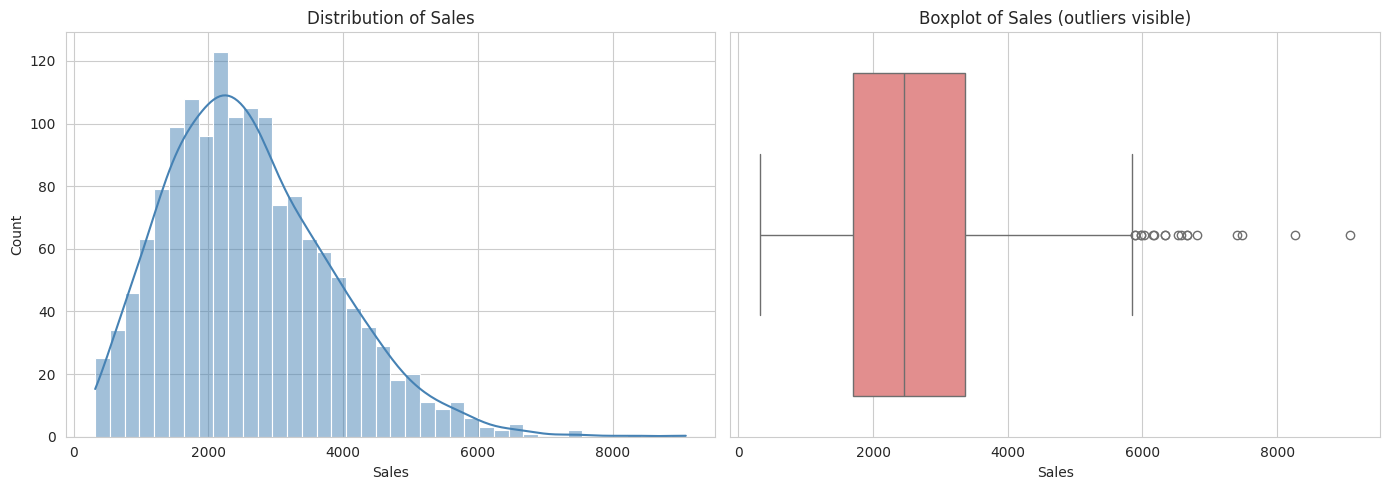

count    1500.000000
mean     2610.205473
std      1242.253612
min       319.520000
25%      1696.577500
50%      2452.555000
75%      3359.382500
max      9087.420000
Name: Sales, dtype: float64


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Sales'], bins=40, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of Sales')
axes[0].set_xlabel('Sales')

sns.boxplot(x=df['Sales'], ax=axes[1], color='lightcoral')
axes[1].set_title('Boxplot of Sales (outliers visible)')

plt.tight_layout()
plt.show()

print(df['Sales'].describe())


### 6.2 Monthly Sales Trend Over Time

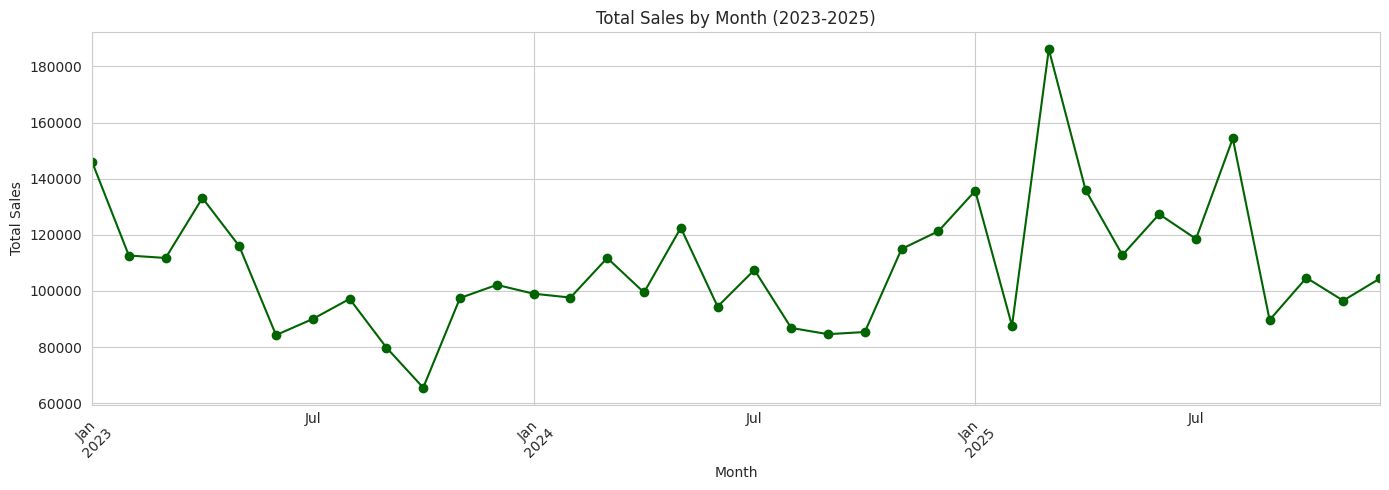

In [14]:
monthly_sales = df.groupby(df['Date'].dt.to_period('M'))['Sales'].sum()

plt.figure(figsize=(14, 5))
monthly_sales.plot(marker='o', color='darkgreen')
plt.title('Total Sales by Month (2023-2025)')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 6.3 Sales by Product Category

/tmp/ipykernel_191/2769305774.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Product_Category', y='Sales', order=order, palette='viridis')


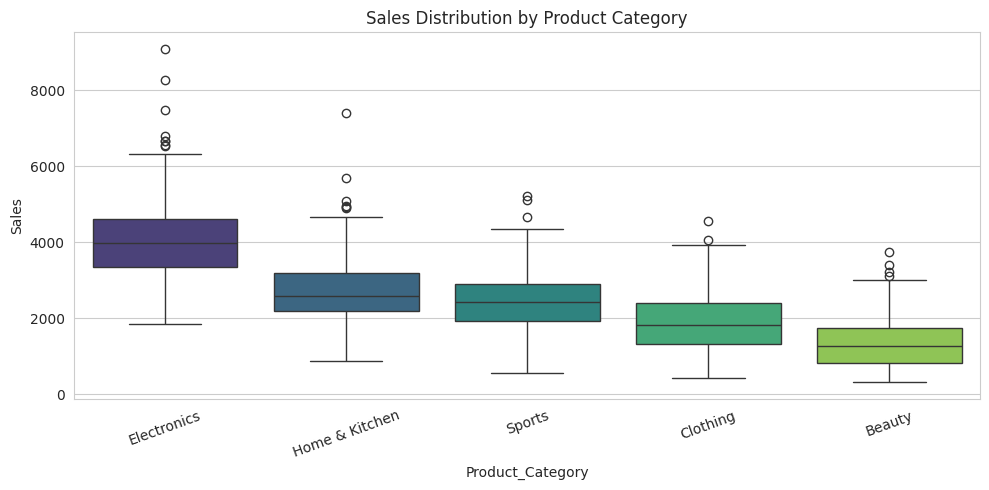

,mean,median,sum
Product_Category,,,
Electronics,4062.761295,3981.110,1474782.35
Home & Kitchen,2711.515374,2578.745,797185.52
Sports,2476.398486,2433.240,703297.17
Clothing,1897.221934,1833.870,627980.46
Beauty,1368.696096,1286.965,312062.71


In [15]:
plt.figure(figsize=(10, 5))
order = df.groupby('Product_Category')['Sales'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='Product_Category', y='Sales', order=order, palette='viridis')
plt.title('Sales Distribution by Product Category')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

df.groupby('Product_Category')['Sales'].agg(['mean', 'median', 'sum']).sort_values('sum', ascending=False)


### 6.4 Sales by Region

/tmp/ipykernel_191/3055453417.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=region_sales.index, y=region_sales.values, palette='mako')


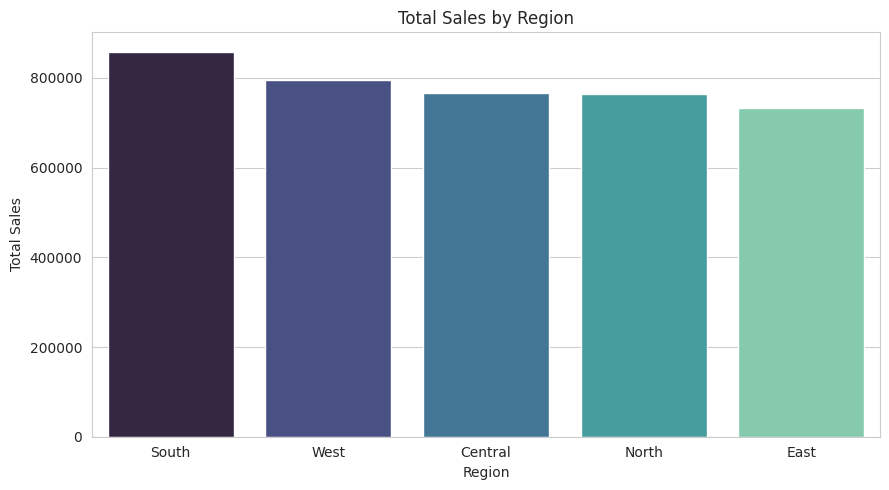

In [16]:
plt.figure(figsize=(9, 5))
region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)
sns.barplot(x=region_sales.index, y=region_sales.values, palette='mako')
plt.title('Total Sales by Region')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()


### 6.5 Effect of Promotion and Holiday on Sales

/tmp/ipykernel_191/2887658315.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Promotion', y='Sales', ax=axes[0], palette='Set2')
/tmp/ipykernel_191/2887658315.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Holiday', y='Sales', ax=axes[1], palette='Set3')


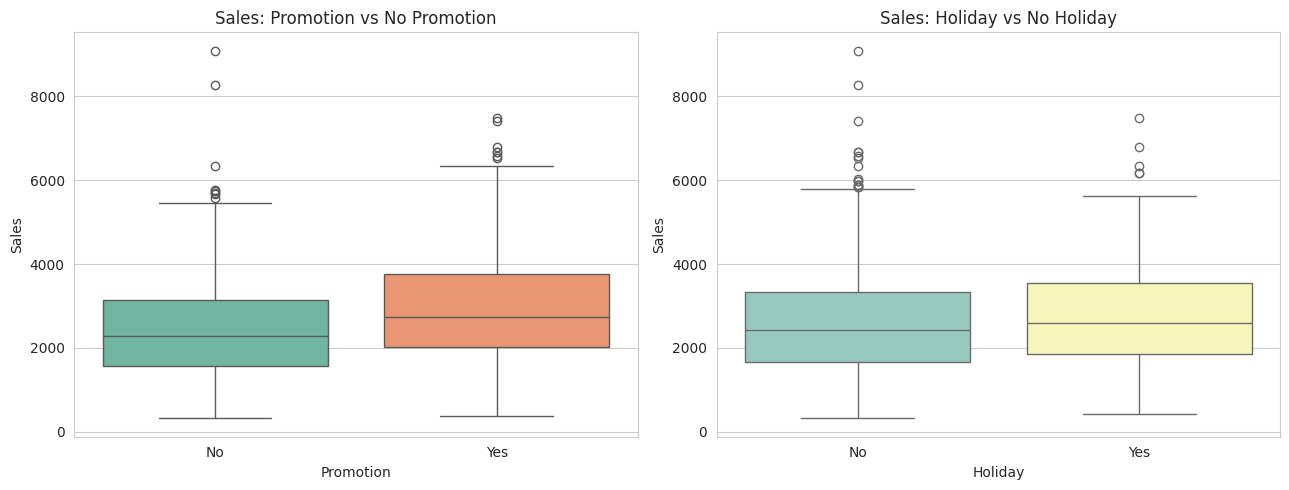

Average sales with promotion: 2939.39
Average sales without promotion: 2435.02


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x='Promotion', y='Sales', ax=axes[0], palette='Set2')
axes[0].set_title('Sales: Promotion vs No Promotion')

sns.boxplot(data=df, x='Holiday', y='Sales', ax=axes[1], palette='Set3')
axes[1].set_title('Sales: Holiday vs No Holiday')

plt.tight_layout()
plt.show()

print("Average sales with promotion:", df[df['Promotion']=='Yes']['Sales'].mean().round(2))
print("Average sales without promotion:", df[df['Promotion']=='No']['Sales'].mean().round(2))


### 6.6 Sales by Day of the Week

/tmp/ipykernel_191/2087246026.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Day_of_Week', y='Sales', order=day_order, estimator=np.mean, palette='coolwarm')


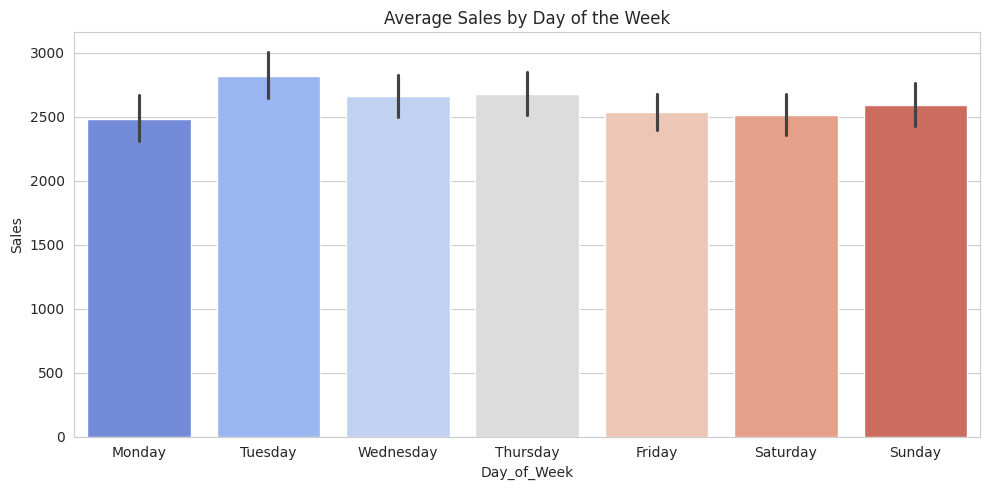

In [18]:
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='Day_of_Week', y='Sales', order=day_order, estimator=np.mean, palette='coolwarm')
plt.title('Average Sales by Day of the Week')
plt.tight_layout()
plt.show()


### 6.7 Correlation Between Numeric Features and Sales

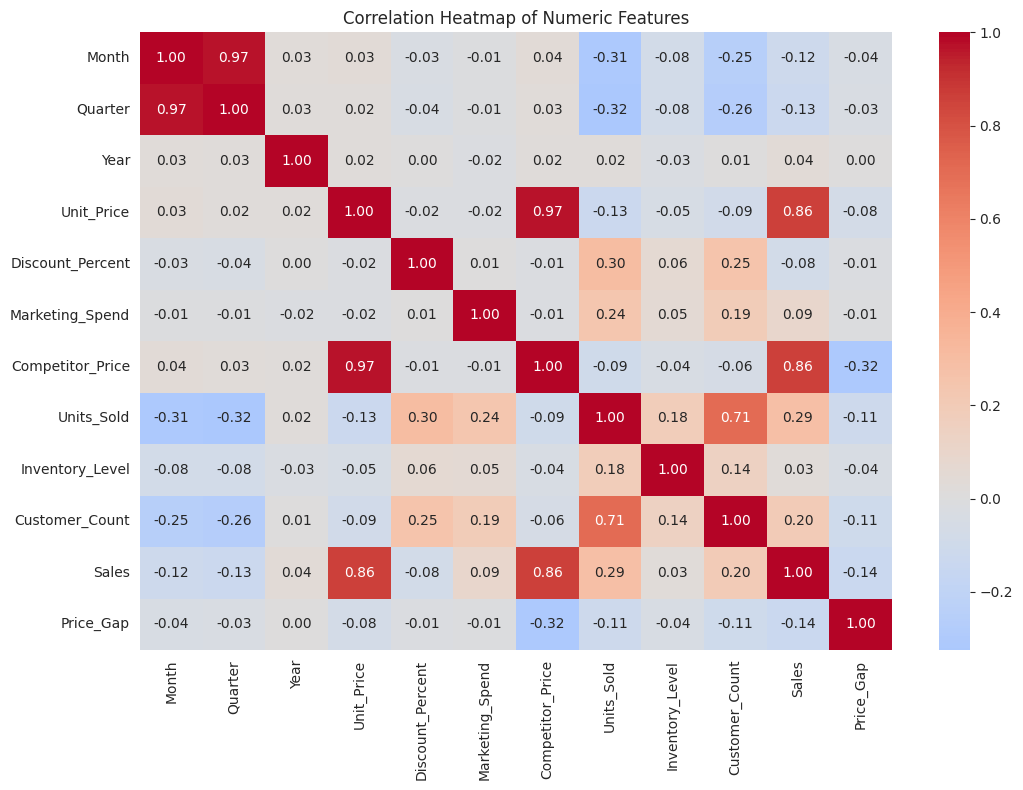

Correlation of each feature with Sales (sorted):
Sales               1.000000
Unit_Price          0.864771
Competitor_Price    0.855952
Units_Sold          0.289920
Customer_Count      0.198775
Marketing_Spend     0.091560
Year                0.036188
Inventory_Level     0.027228
Discount_Percent   -0.083346
Month              -0.115798
Quarter            -0.128004
Price_Gap          -0.137325
Name: Sales, dtype: float64


In [19]:
numeric_df = df.select_dtypes(include=np.number)
corr_matrix = numeric_df.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()

print("Correlation of each feature with Sales (sorted):")
print(corr_matrix['Sales'].sort_values(ascending=False))


### 6.8 Relationship of Key Drivers with Sales

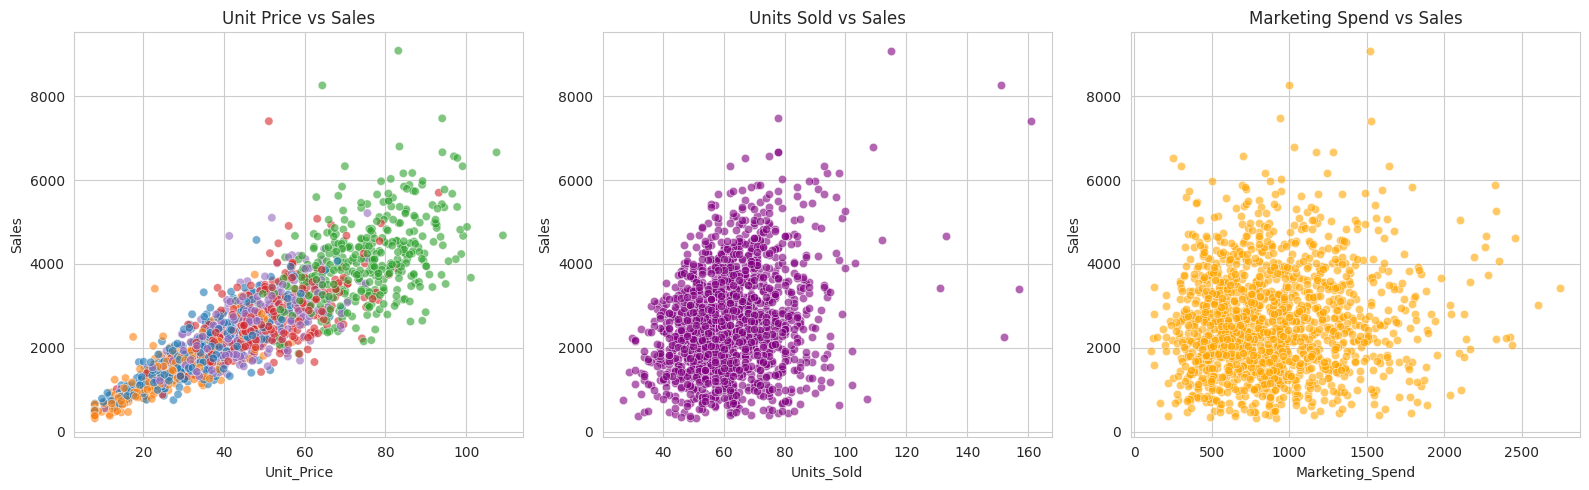

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.scatterplot(data=df, x='Unit_Price', y='Sales', hue='Product_Category', ax=axes[0], alpha=0.6, legend=False)
axes[0].set_title('Unit Price vs Sales')

sns.scatterplot(data=df, x='Units_Sold', y='Sales', ax=axes[1], alpha=0.6, color='purple')
axes[1].set_title('Units Sold vs Sales')

sns.scatterplot(data=df, x='Marketing_Spend', y='Sales', ax=axes[2], alpha=0.6, color='orange')
axes[2].set_title('Marketing Spend vs Sales')

plt.tight_layout()
plt.show()


## 7. Key Insights from EDA

- **No structural data problems**: dataset has no duplicate rows; missing values were limited to
  4 numeric columns (~0.8% of rows) and have been imputed category-wise.
- **`Sales` is right-skewed** with a small number of high-value outlier days (~18 rows), likely
  linked to promotions or high-demand products rather than data errors.
- **`Unit_Price` and `Competitor_Price` show the strongest positive correlation with `Sales`**
  (~0.86), followed by `Units_Sold` (~0.29) and `Customer_Count` (~0.20).
- **`Month`/`Quarter` show a weak negative correlation with `Sales`**, hinting at a mild seasonal
  pattern worth exploring further with time-series decomposition in Phase 2.
- **Promotions correspond to a visible uplift** in average sales compared to non-promotion days.
- Category and region differences exist, but are less pronounced than price-driven effects —
  these will still be encoded as categorical features for the model.

## 8. Next Steps (Phase 2 — mapped to remaining COs)

| Task | CO |
|---|---|
| Encode categorical features, scale numeric features, engineer date-based & lag features | CO2 |
| Train baseline models (Linear/Ridge/Lasso Regression) for comparison | CO2 |
| Train Gradient-Boosted Trees (XGBoost/LightGBM) as the primary model | CO3 |
| Train/Validation/Test split, K-Fold Cross-Validation | CO5 |
| Grid-Search Hyperparameter Tuning | CO5 |
| Evaluate using MAE, RMSE, R² | CO5 |
| Package the final model and design a REST prediction API | CO6 |
| Add monitoring for data/performance drift | CO6 |

This notebook (Phase 1) will feed directly into the feature engineering and modelling notebook
of Phase 2.
